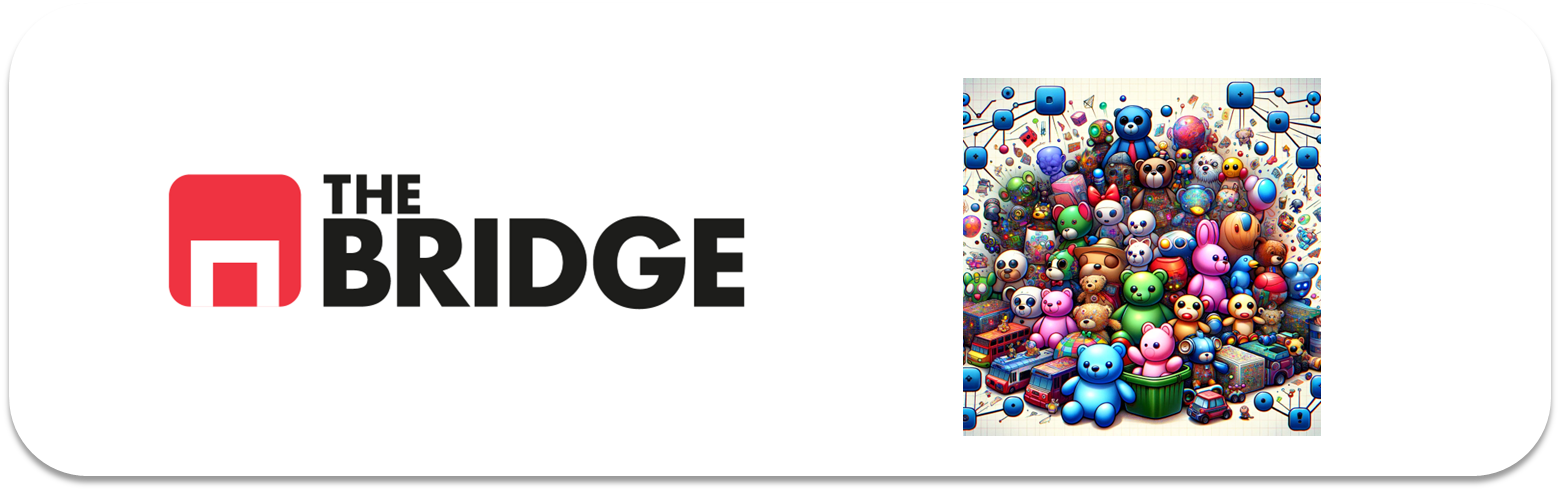

## PRÁCTICA: **Clustering con K-Means y DBSCAN**

* La práctica de esta unidad consiste en segmentar un dataset tabular sin target: usarás la PCA para visualizar los datos, K-Means y DBSCAN para encontrar los grupos y, al final, compararás y evaluarás los resultados de ambos algoritmos.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, silhouette_score

pd.options.mode.copy_on_write = True # CoW por defecto a partir de pandas 3.0.0

### El problema de negocio

En una planta de experimentación con nuevas bebidas energéticas están trabajando con diferentes mezclas de componentes para obtener posibles variedades de su producto estrella "NonstopU". El problema es que la fabricación de cada "prototipo" conlleva demasiado tiempo y las pruebas de sabores y de propiedades "non-stop" antisueño y antifatiga son costosas.

Por eso quieren construir un sistema de segmentación previa de las mezclas, sin probarlas, solo a partir de las cantidades de cada componente de la bebida. Tienen datos de mezclas anteriores pero, por temas presupuestarios y de prioridad, nunca se probaron con usuarios ni con potenciales clientes. Es decir, no tienen un target de capacidad antifatiga o de preferencia del usuario que les sirva para construir un clasificador clásico, como han hecho otras veces.

Han acudido a vosotros para que les ayudéis a encontrar algún tipo de segmentación de esas mezclas, que luego ellos se encargarán de interpretar.

NOTA ORIENTATIVA: Los químicos no esperan que haya menos de 3 segmentos ni más de 5.
NOTA OPERATIVA: El dataset con los datos que nos han dado los químicos está en `../data/empowering_drinks.csv` (separador `|`).

### #1 EXPLORACIÓN Y VISUALIZACIÓN CON PCA

#### #1.1

Carga los datos y haz un miniEDA rápido: ¿hay nulos?, ¿de qué tipo son las variables?, ¿hace falta escalarlas o transformarlas? Recuerda que tanto K-Means como DBSCAN trabajan con distancias.

In [2]:
df = pd.read_csv("../data/empowering_drinks.csv", sep = "|")
df

,Azúcares,Vitaminas del grupo B,Cafeína,Ácido Cítrico,Taurina
0,1.518613,0.232053,1.034819,1.013009,0.251717
1,0.246290,-0.827996,0.733629,0.965242,-0.293321
2,0.196879,1.109334,1.215533,1.395148,0.269020
3,1.691550,0.487926,1.466525,2.334574,1.186068
4,0.295700,1.840403,0.663351,-0.037874,-0.319276
...,...,...,...,...,...
148,0.493343,0.414820,-1.284344,0.009893,0.969783
149,0.332758,-0.389355,-1.344582,0.280575,2.224236
150,0.209232,0.012732,-1.354622,0.296498,1.834923
151,1.395086,1.365208,-1.274305,-0.595160,1.791666


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Azúcares               153 non-null    float64
 1   Vitaminas del grupo B  153 non-null    float64
 2   Cafeína                153 non-null    float64
 3   Ácido Cítrico          153 non-null    float64
 4   Taurina                153 non-null    float64
dtypes: float64(5)
memory usage: 6.1 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Azúcares,153.0,0.019231,1.026182,-2.434235,-0.816038,0.061000,0.876275,2.259772
Vitaminas del grupo B,153.0,0.037273,0.995984,-3.679162,-0.499016,-0.023821,0.707247,3.156325
Cafeína,153.0,0.041057,1.040928,-1.695971,-1.043392,0.211566,0.894264,3.062832
Ácido Cítrico,153.0,0.080022,1.009450,-1.493188,-0.738463,-0.165254,0.917474,2.971473
Taurina,153.0,-0.044088,0.934399,-1.634288,-0.799428,-0.154899,0.493956,2.431870


*153 mezclas, 5 variables numéricas y ningún nulo. Las medias están cerca de 0 y las desviaciones típicas cerca de 1: los datos ya vienen estandarizados. Conviene comprobarlo siempre, porque K-Means y DBSCAN trabajan con distancias y una variable con mayor escala dominaría a las demás.*

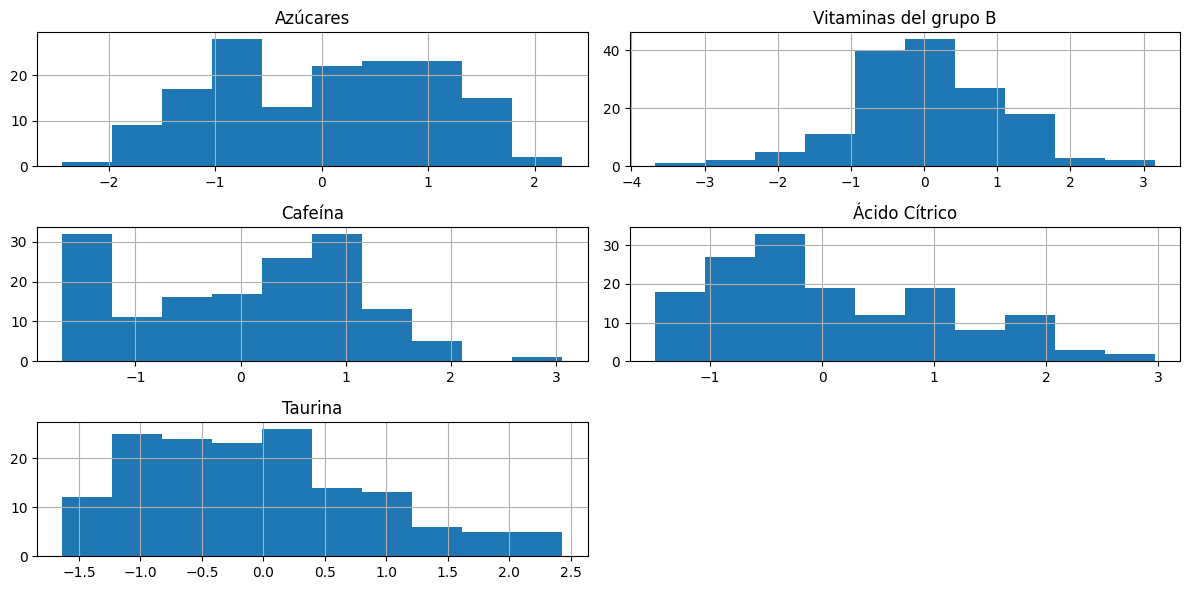

In [5]:
df.hist(figsize = (12, 6))
plt.tight_layout()
plt.show()

*Ninguna distribución es muy asimétrica y todas están en rangos parecidos, así que no transformamos nada. Fíjate, eso sí, en que Cafeína o Azúcares tienen varias "jorobas": es una primera pista de que puede haber grupos distintos de mezclas.*

#### #1.2

Con 5 variables hay 10 parejas posibles: revisarlas una a una con scatter plots es lento y, con más variables, sería inviable. En su lugar, aplica una PCA sobre los datos y muestra la varianza explicada acumulada. ¿Qué porcentaje de la varianza recogen las dos primeras componentes? ¿Es suficiente para usarlas como "foto" de los datos?

In [6]:
pca = PCA()
X_pca = pca.fit_transform(df)

pca.explained_variance_ratio_.cumsum()

array([0.46945422, 0.70194206, 0.8818616 , 0.9448574 , 1.        ])

*Las dos primeras componentes recogen el 70% de la varianza. No basta para sustituir a los datos originales (por eso entrenaremos los modelos con las 5 variables), pero sí para tener una "foto" bastante fiel de cómo se distribuyen las mezclas.*

#### #1.3

Representa las mezclas en el plano PC1-PC2 con un **biplot** (puntos y flechas con los loadings de cada variable, como vimos en la unidad de PCA). ¿Se intuyen grupos? ¿Cuántos? ¿Qué variables parecen separarlos?

NOTA: Usaremos la PCA solo para visualizar. Los modelos de clustering se entrenarán con las 5 variables originales.

*Como vamos a pintar el biplot varias veces (sin etiquetas, con los clusters de K-Means, con los de DBSCAN...), lo convertimos en una función:*

In [7]:
df_pca = pd.DataFrame(X_pca[:, :2], columns = ["PC1", "PC2"])

def pinta_biplot(df_pca, pca, features, etiquetas = None, nuevos = None, titulo = "Biplot", escala = 3):
    fig, ax = plt.subplots(figsize = (10, 8))
    if etiquetas is None:
        sns.scatterplot(x = df_pca["PC1"], y = df_pca["PC2"], alpha = 0.8, ax = ax)
    else:
        hue = pd.Series(etiquetas).astype(str) # Etiquetas como texto para que se pinten como categorías
        orden = sorted(hue.unique())
        colores = dict(zip(orden, sns.color_palette("Set2", len(orden))))
        if "Anomalía" in colores:
            colores["Anomalía"] = "black" # Las anomalías de DBSCAN, en negro para que destaquen
        sns.scatterplot(x = df_pca["PC1"], y = df_pca["PC2"], hue = hue, hue_order = orden, palette = colores, alpha = 0.8, ax = ax)
        ax.legend(title = "Cluster")

    if nuevos is not None: # Proyecciones de nuevas instancias, si las hay
        ax.scatter(nuevos["PC1"], nuevos["PC2"], marker = "X", s = 200, color = "red", label = "Nuevos")
        ax.legend()

    for i, feature in enumerate(features):
        x, y = pca.components_[0, i] * escala, pca.components_[1, i] * escala # Los loadings son menores que 1, los alargamos para que se vean
        ax.arrow(0, 0, x, y, color = "darkred", head_width = 0.08)
        ax.text(x * 1.12, y * 1.12, feature, color = "darkred", fontsize = 12)

    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
    ax.set_title(titulo)
    plt.show()

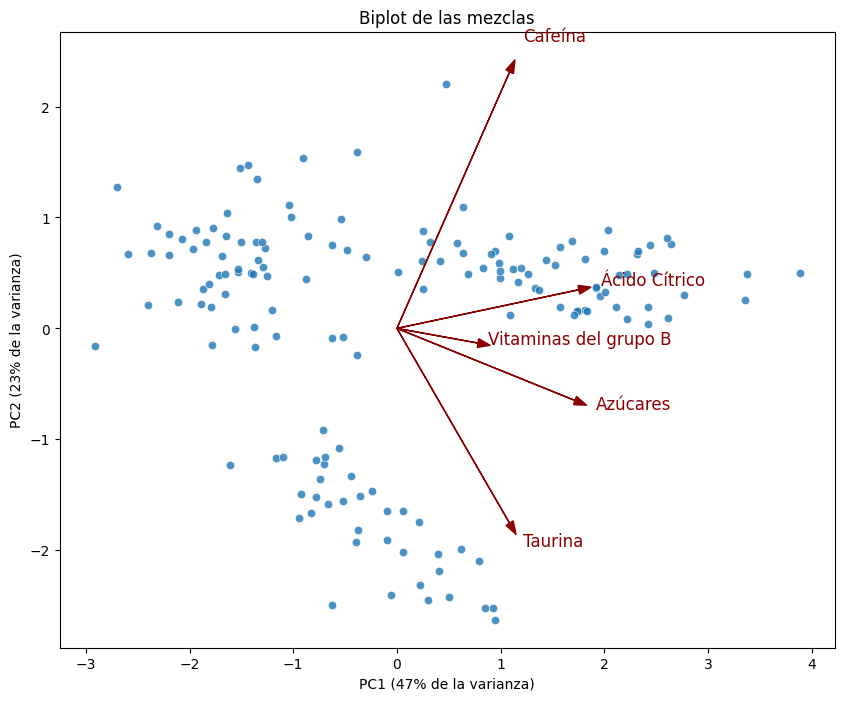

In [8]:
pinta_biplot(df_pca, pca, df.columns, titulo = "Biplot de las mezclas")

In [9]:
pd.DataFrame(pca.components_[:2], columns = df.columns, index = ["PC1", "PC2"]).round(2)

,Azúcares,Vitaminas del grupo B,Cafeína,Ácido Cítrico,Taurina
PC1,0.57,0.26,0.36,0.58,0.36
PC2,-0.22,-0.04,0.77,0.12,-0.59


*En el biplot se ven claramente **tres grupos** de mezclas, dentro del rango de 3 a 5 que esperaban los químicos:*
* *A la derecha (PC1 alta), mezclas con más cantidad de casi todo, sobre todo de Ácido Cítrico y Azúcares: PC1 tiene loadings positivos en todas las variables, y los mayores son los de esas dos.*
* *Arriba a la izquierda (PC1 baja, PC2 positiva), mezclas con menos cantidad de casi todo y relativamente más Cafeína que Taurina.*
* *Abajo (PC2 muy negativa), mezclas con mucha Taurina y poca Cafeína: PC2 enfrenta precisamente esas dos variables (loading de +0,77 en Cafeína y de −0,59 en Taurina).*

*Con una sola figura hemos llegado más lejos que mirando los 10 scatter plots de parejas de variables: además de los grupos, el biplot nos dice qué variables los separan.*

### #2 K-MEANS

#### #2.1

Entrena K-Means para valores de k entre 2 y 8 y escoge el número de clusters con el método de la silueta y con el del codo de la inercia. ¿Coinciden entre sí? ¿Y con lo que intuiste en el biplot y con la nota orientativa de los químicos?

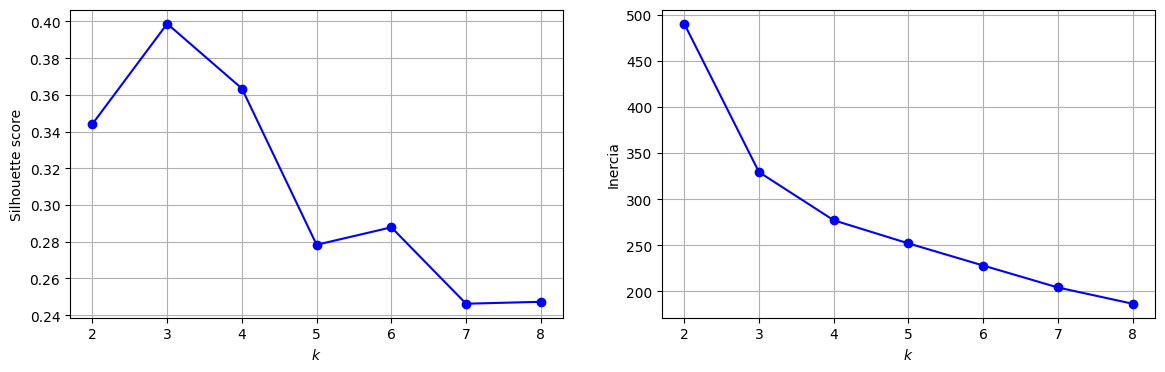

In [10]:
k_range = range(2, 9)
kmeans_por_k = [KMeans(n_clusters = k, n_init = 10, random_state = 42).fit(df) for k in k_range]

siluetas = [silhouette_score(df, modelo.labels_) for modelo in kmeans_por_k]
inercias = [modelo.inertia_ for modelo in kmeans_por_k]

fig, axs = plt.subplots(1, 2, figsize = (14, 4))
axs[0].plot(k_range, siluetas, "bo-")
axs[0].set_xlabel("$k$")
axs[0].set_ylabel("Silhouette score")
axs[0].grid()
axs[1].plot(k_range, inercias, "bo-")
axs[1].set_xlabel("$k$")
axs[1].set_ylabel("Inercia")
axs[1].grid()
plt.show()

*Los dos métodos coinciden: la silueta tiene un máximo claro en k = 3 y el codo de la inercia también está en k = 3 (a partir de ahí la inercia baja mucho más despacio). Encaja con los tres grupos del biplot y con la nota orientativa de los químicos.*

#### #2.2

Entrena el modelo con el k escogido, muestra cuántas mezclas caen en cada cluster y visualiza los clusters sobre el biplot.

In [11]:
kmeans = KMeans(n_clusters = 3, n_init = 10, random_state = 42)
kmeans.fit(df)

pd.Series(kmeans.labels_).value_counts()

2    58
0    58
1    37
Name: count, dtype: int64

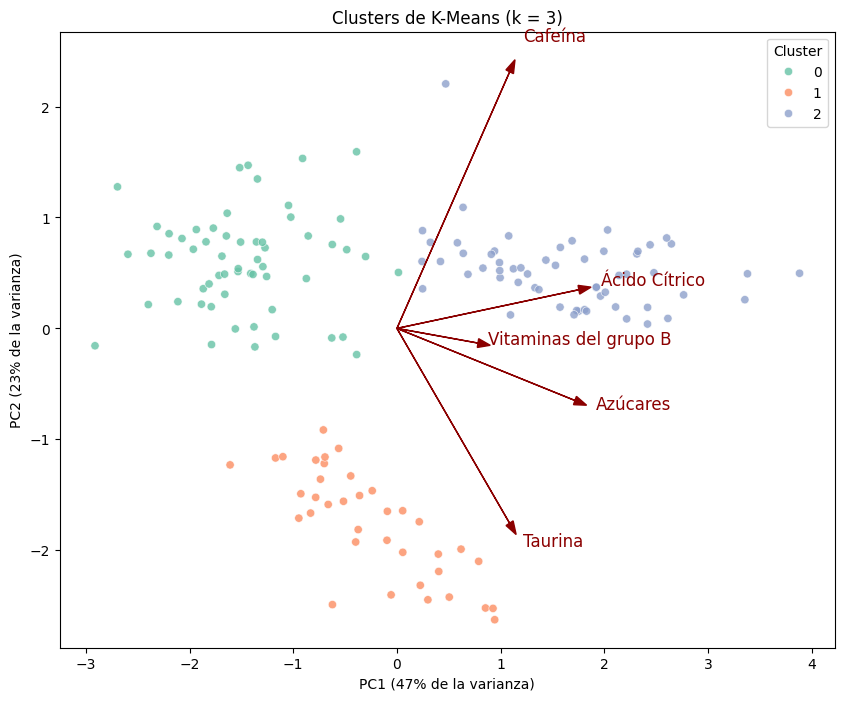

In [12]:
pinta_biplot(df_pca, pca, df.columns, etiquetas = kmeans.labels_, titulo = "Clusters de K-Means (k = 3)")

*K-Means recupera los tres grupos del biplot (58, 58 y 37 mezclas). Las únicas dudas están en la zona central, donde los grupos de la izquierda y de la derecha se acercan: K-Means asigna cada mezcla al centroide más cercano, así que la frontera entre dos clusters es siempre una "línea recta" (celdas de Voronoi), haya o no puntos en medio.*

### #3 DBSCAN

#### #3.1

Ajusta los hiperparámetros `eps` y `min_samples`: para varios valores de `min_samples` (por ejemplo 3, 5 y 10), recorre un rango de valores de `eps` y registra el número de clusters y el porcentaje de anomalías que obtienes. Escoge la combinación que dé entre 3 y 5 clusters con el menor porcentaje de anomalías posible y justifica tu elección.

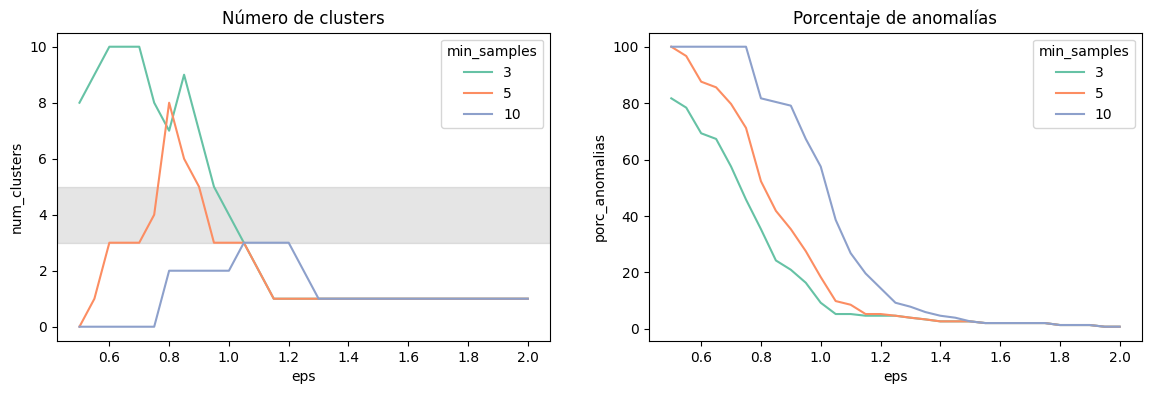

In [13]:
valores_eps = np.round(np.arange(0.5, 2.01, 0.05), 2)
resultados = []

for min_samples in [3, 5, 10]:
    for eps in valores_eps:
        etiquetas = DBSCAN(eps = eps, min_samples = min_samples).fit(df).labels_
        resultados.append({
            "min_samples": min_samples,
            "eps": eps,
            "num_clusters": len(set(etiquetas) - {-1}), # Las anomalías (-1) no son un cluster
            "porc_anomalias": round(100 * np.mean(etiquetas == -1), 1),
        })

df_dbscan = pd.DataFrame(resultados)

fig, axs = plt.subplots(1, 2, figsize = (14, 4))
sns.lineplot(data = df_dbscan, x = "eps", y = "num_clusters", hue = "min_samples", palette = "Set2", ax = axs[0])
axs[0].axhspan(3, 5, color = "grey", alpha = 0.2) # Rango orientativo de los químicos
axs[0].set_title("Número de clusters")
sns.lineplot(data = df_dbscan, x = "eps", y = "porc_anomalias", hue = "min_samples", palette = "Set2", ax = axs[1])
axs[1].set_title("Porcentaje de anomalías")
plt.show()

In [14]:
candidatos = df_dbscan[df_dbscan["num_clusters"].between(3, 5)].sort_values("porc_anomalias")
candidatos

,min_samples,eps,num_clusters,porc_anomalias
11,3,1.05,3,5.2
10,3,1.00,4,9.2
42,5,1.05,3,9.8
76,10,1.20,3,14.4
9,3,0.95,5,16.3
41,5,1.00,3,18.3
75,10,1.15,3,19.6
74,10,1.10,3,26.8
40,5,0.95,3,27.5
39,5,0.90,5,35.3


*Las curvas muestran lo delicado que es ajustar DBSCAN en este dataset: con `eps` pequeños casi todo es anomalía o salen muchos clusters diminutos, y a partir de `eps` ≈ 1,1-1,3 los grupos se fusionan en uno solo. La ventana útil es muy estrecha.*

*La combinación con menos anomalías que da entre 3 y 5 clusters es `eps` = 1,05 y `min_samples` = 3: 3 clusters y un 5,2% de anomalías. Y es muy sensible: con `eps` = 1,0 salen 4 clusters (uno de solo 4 mezclas) y con `eps` = 1,1 dos grupos ya se fusionan y quedan 2.*

#### #3.2

Entrena DBSCAN con los hiperparámetros escogidos, muestra cuántas mezclas caen en cada cluster (y cuántas son anomalías) y visualiza el resultado sobre el biplot.

In [15]:
dbscan = DBSCAN(eps = 1.05, min_samples = 3)
dbscan.fit(df)

pd.Series(dbscan.labels_).value_counts()

 0    59
 1    49
 2    37
-1     8
Name: count, dtype: int64

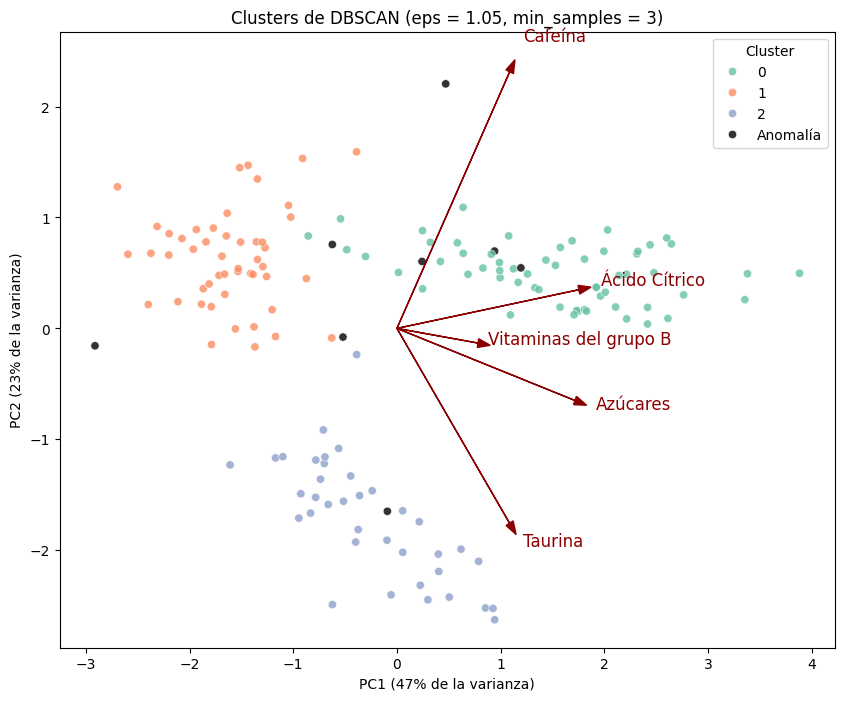

In [16]:
etiquetas_dbscan = np.where(dbscan.labels_ == -1, "Anomalía", dbscan.labels_.astype(str))
pinta_biplot(df_pca, pca, df.columns, etiquetas = etiquetas_dbscan, titulo = "Clusters de DBSCAN (eps = 1.05, min_samples = 3)")

*DBSCAN también encuentra tres grupos (59, 49 y 37 mezclas) y marca 8 mezclas como anomalías, sobre todo en las zonas poco densas entre grupos y en los extremos. Pero fíjate en la zona central: el cluster de la derecha "se estira" hacia la izquierda y se queda con algunas mezclas que, a simple vista, parecen del grupo de arriba a la izquierda. Es el efecto "cadena" de DBSCAN: si hay una sucesión de puntos lo bastante densa, conecta zonas que visualmente consideraríamos grupos distintos.*

*Recuerda además que estamos viendo una proyección en 2D (70% de la varianza): dos mezclas que parecen cercanas en el biplot pueden estar más lejos en las 5 dimensiones originales.*

### #4 COMPARACIÓN Y REFLEXIÓN

#### #4.1

Compara las etiquetas de los dos modelos con una tabla cruzada (`pd.crosstab`). Ojo: el número que cada algoritmo asigna a un cluster es arbitrario, así que el cluster 0 de K-Means no tiene por qué ser el cluster 0 de DBSCAN.

In [17]:
pd.crosstab(kmeans.labels_, dbscan.labels_, rownames = ["K-Means"], colnames = ["DBSCAN"])

DBSCAN,-1,0,1,2
K-Means,,,,
0,3,5,49,1
1,1,0,0,36
2,4,54,0,0


*Quitando la diferencia de nombres, los dos modelos coinciden en casi todo: el cluster 0 de K-Means corresponde al 1 de DBSCAN, el 1 al 2 y el 2 al 0. Las diferencias son las 8 anomalías de DBSCAN (que K-Means asigna a algún cluster) y 6 mezclas de la zona central que cada algoritmo coloca en un grupo distinto.*

#### #4.2

Reflexiona sobre los resultados:
* ¿Qué algoritmo ha sido más fácil de ajustar? ¿Cómo de sensible es cada uno a sus hiperparámetros?
* ¿Qué forma de cluster asume cada algoritmo? ¿Qué hace cada uno con las mezclas "dudosas" o alejadas?
* ¿Con cuál te quedarías para entregárselo a los químicos y por qué?
* ¿Por qué cualquier comparación que hagamos en este punto es especulativa?

* *Facilidad de ajuste: K-Means solo necesita k, y tanto la silueta como el codo apuntan claramente a 3. DBSCAN necesita dos hiperparámetros y aquí solo una ventana muy estrecha de `eps` da un resultado razonable: con 5 dimensiones y 153 mezclas, la densidad no cambia tanto entre los grupos y las zonas intermedias.*
* *Forma de los clusters: K-Means asume grupos compactos y "redondeados" alrededor de un centroide, que es justo lo que vemos en el biplot. DBSCAN puede encontrar grupos de cualquier forma, pero por eso mismo puede encadenar grupos a través de zonas intermedias.*
* *Mezclas dudosas: K-Means asigna siempre todas las mezclas a algún grupo; DBSCAN deja 8 sin segmento. Para los químicos puede ser un valor añadido (mezclas "raras" que conviene revisar) o un inconveniente (mezclas que no sabemos clasificar).*
* *Elección: aquí nos quedaríamos con K-Means: es más sencillo, más estable ante cambios de hiperparámetros, segmenta todas las mezclas y tiene `predict` para las nuevas. DBSCAN tendría más sentido con grupos de formas irregulares o si detectar anomalías fuese un objetivo en sí mismo.*
* *¿Por qué es especulativo? Porque no tenemos target: no hay una "respuesta correcta" contra la que medir. La silueta, la inercia o el porcentaje de anomalías nos dicen si los grupos son compactos o densos, no si tienen sentido para el negocio. Eso solo pueden decirlo los químicos... o unos datos que todavía no tenemos.*

### #5 NUEVOS EXPERIMENTOS

Los químicos están muy esperanzados con los modelos que les habéis mostrado y os pasan una lista de nuevos experimentos para que los segmentéis. Los tienes en `../data/new_experiments.csv`.

Asigna cada nuevo experimento a un segmento con los dos modelos y visualízalos sobre el biplot. PISTA: K-Means tiene método `predict`, pero DBSCAN no. ¿Por qué? ¿Cómo puedes resolverlo? (recuerda lo que vimos en la teoría).

In [18]:
df_nuevos = pd.read_csv("../data/new_experiments.csv", sep = "|")
df_nuevos

,Azúcares,Vitaminas del grupo B,Cafeína,Ácido Cítrico,Taurina
0,1.481555,0.305159,1.366128,2.239039,0.731870
1,0.616869,0.890014,0.583034,0.312420,-0.665332
2,-1.680724,0.341713,-0.340615,-0.213021,-0.976782
3,-0.284874,-1.412851,-0.782361,-1.193845,-0.717240
4,-0.927212,0.634140,-1.565455,-0.085641,-0.522583
5,0.962743,-0.243142,-1.354622,-0.420013,1.956043


*K-Means asigna cada punto al centroide más cercano, así que puede etiquetar directamente cualquier mezcla nueva:*

In [19]:
nuevos_kmeans = kmeans.predict(df_nuevos)
nuevos_kmeans

array([2, 2, 0, 0, 1, 1])

*DBSCAN no tiene `predict` porque no construye ninguna frontera ni centroide: sus clusters se definen por la densidad de los puntos del propio dataset de entrenamiento. Como vimos en la teoría, la solución es entrenar un clasificador supervisado (por ejemplo, un Random Forest) usando como target las etiquetas de DBSCAN.*

*Lo entrenamos sin las anomalías, porque no forman un grupo con sentido propio: así cada nueva mezcla se asigna a uno de los tres clusters.*

In [20]:
es_anomalia = dbscan.labels_ == -1

rf = RandomForestClassifier(random_state = 42)
rf.fit(df[~es_anomalia], dbscan.labels_[~es_anomalia])

nuevos_dbscan = rf.predict(df_nuevos)
nuevos_dbscan

array([0, 0, 1, 1, 2, 2], dtype=int64)

In [21]:
df_nuevos_res = df_nuevos.copy()
df_nuevos_res["Cluster_KMeans"] = nuevos_kmeans
df_nuevos_res["Cluster_DBSCAN"] = nuevos_dbscan
df_nuevos_res

,Azúcares,Vitaminas del grupo B,Cafeína,Ácido Cítrico,Taurina,Cluster_KMeans,Cluster_DBSCAN
0,1.481555,0.305159,1.366128,2.239039,0.731870,2,0
1,0.616869,0.890014,0.583034,0.312420,-0.665332,2,0
2,-1.680724,0.341713,-0.340615,-0.213021,-0.976782,0,1
3,-0.284874,-1.412851,-0.782361,-1.193845,-0.717240,0,1
4,-0.927212,0.634140,-1.565455,-0.085641,-0.522583,1,2
5,0.962743,-0.243142,-1.354622,-0.420013,1.956043,1,2


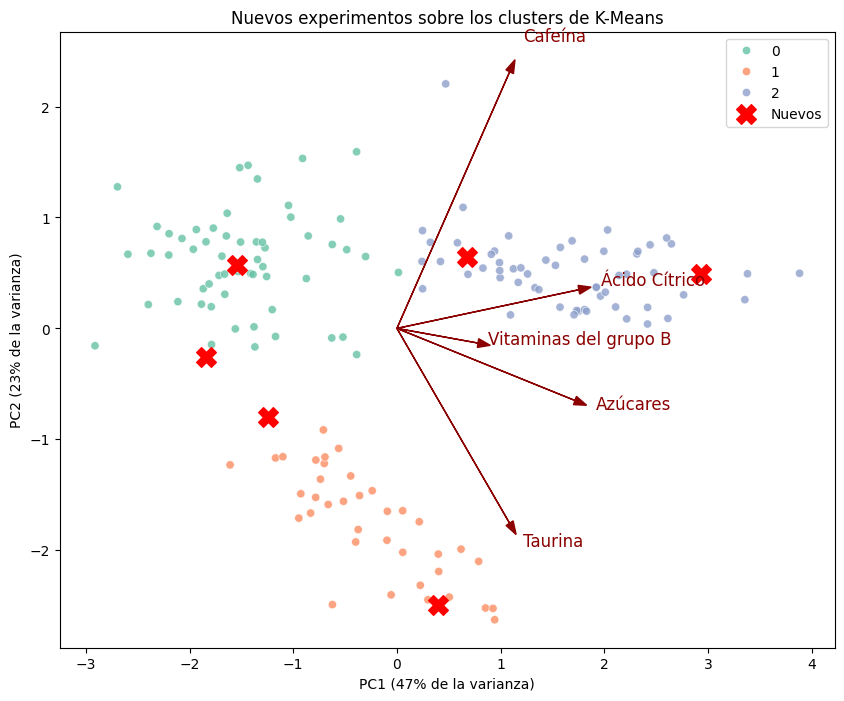

In [22]:
nuevos_pca = pd.DataFrame(pca.transform(df_nuevos)[:, :2], columns = ["PC1", "PC2"]) # Misma proyección que el train

pinta_biplot(df_pca, pca, df.columns, etiquetas = kmeans.labels_, nuevos = nuevos_pca, titulo = "Nuevos experimentos sobre los clusters de K-Means")

*Los dos modelos asignan los 6 nuevos experimentos a los mismos grupos (con distinto número de etiqueta): los dos primeros al grupo de la derecha, los dos siguientes al de arriba a la izquierda y los dos últimos al de abajo. En el biplot se ve que la mayoría caen dentro de su grupo, aunque alguno queda en una zona intermedia, donde la asignación es menos segura.*

### #6 SEIS MESES DESPUÉS...

La unidad de experimentación recibió un presupuesto adicional gracias a los modelos que les proporcionasteis, hizo pruebas con clientes y obtuvo resultados suficientes para clasificar cada bebida en términos de "energización" en tres niveles (1, media; 2, media-alta; 3, alta). Los resultados están en `../data/power_results.csv`, alineados primero con los experimentos iniciales y, al final, con los nuevos experimentos de la parte anterior.

Evalúa la segmentación de los dos modelos:
1. "Traduce" cada cluster a la clase real que mejor le corresponde (una tabla cruzada te ayudará).
2. Mide el resultado con un `classification_report` sobre todas las mezclas (las iniciales y las nuevas). En DBSCAN, decide qué hacer con las anomalías.
3. ¿Se confirman las conclusiones de la parte 4? ¿Con qué modelo te quedarías ahora?

In [23]:
y_real = pd.read_csv("../data/power_results.csv", sep = "|")["class"]
y_real_train = y_real[:len(df)].values # Los 153 experimentos iniciales
y_real.value_counts()

class
2    62
1    58
3    39
Name: count, dtype: int64

**K-Means**

In [24]:
tabla_kmeans = pd.crosstab(kmeans.labels_, y_real_train, rownames = ["Cluster K-Means"], colnames = ["Clase real"])
tabla_kmeans

Clase real,1,2,3
Cluster K-Means,,,
0,1,57,0
1,0,0,37
2,55,3,0


In [25]:
mapa_kmeans = tabla_kmeans.idxmax(axis = 1) # Para cada cluster, la clase real más frecuente
mapa_kmeans

Cluster K-Means
0    2
1    3
2    1
dtype: int64

In [26]:
y_pred_kmeans = pd.Series(np.concatenate([kmeans.labels_, nuevos_kmeans])).map(mapa_kmeans)
print(classification_report(y_real, y_pred_kmeans))

              precision    recall  f1-score   support

           1       0.95      0.98      0.97        58
           2       0.98      0.95      0.97        62
           3       1.00      1.00      1.00        39

    accuracy                           0.97       159
   macro avg       0.98      0.98      0.98       159
weighted avg       0.98      0.97      0.97       159



**DBSCAN**

In [27]:
tabla_dbscan = pd.crosstab(dbscan.labels_, y_real_train, rownames = ["Cluster DBSCAN"], colnames = ["Clase real"])
tabla_dbscan

Clase real,1,2,3
Cluster DBSCAN,,,
-1,2,5,1
0,54,5,0
1,0,49,0
2,0,1,36


In [28]:
mapa_dbscan = tabla_dbscan.drop(index = -1).idxmax(axis = 1) # Las anomalías no se traducen a ninguna clase
mapa_dbscan

Cluster DBSCAN
0    1
1    2
2    3
dtype: int64

In [29]:
etiquetas_dbscan_todas = np.concatenate([dbscan.labels_, nuevos_dbscan])
asignadas = etiquetas_dbscan_todas != -1
print(f"Mezclas sin segmento (anomalías): {np.sum(~asignadas)} de {len(asignadas)}")

y_pred_dbscan = pd.Series(etiquetas_dbscan_todas[asignadas]).map(mapa_dbscan)
print(classification_report(y_real[asignadas], y_pred_dbscan))

Mezclas sin segmento (anomalías): 8 de 159
              precision    recall  f1-score   support

           1       0.92      1.00      0.96        56
           2       1.00      0.89      0.94        57
           3       0.97      1.00      0.99        38

    accuracy                           0.96       151
   macro avg       0.96      0.96      0.96       151
weighted avg       0.96      0.96      0.96       151



*Ahora sí podemos medir:*
* *K-Means acierta el 97% de las 159 mezclas (las 153 iniciales y las 6 nuevas) y clasifica perfectamente el nivel de energización 3 (alta).*
* *DBSCAN acierta el 96% de las mezclas a las que asigna segmento, pero deja sin segmentar 8 de las 159 (las anomalías, que en realidad pertenecen a las tres clases). Sus errores se concentran en la clase 2 (recall de 0,89): son las mezclas de la zona central que el efecto cadena unía al cluster de la clase 1.*
* *Los 6 nuevos experimentos quedan bien clasificados con los dos modelos.*

*Se confirman las conclusiones de la parte 4: en este problema, con grupos compactos y bien separados, K-Means es la mejor opción. Y los clusters no eran solo una curiosidad geométrica: corresponden a los tres niveles de energización (media, media-alta y alta) que los químicos han medido después.*

*Eso sí, esto no siempre será así: en otro problema, con otros datos, la segmentación que encontremos no tiene por qué coincidir con el target que nos interesa.*